# Ngô Minh Khôi - 6451071037
## Môn học: IT1.231.3 - Khai thác dữ liệu
### Bai2

### Câu 1

In [1]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 1: Đọc dữ liệu Online Retail và hiển thị thông tin
import pandas as pd

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/Online Retail.xlsx")

print("--- Thông tin tập dữ liệu (df.info()) ---")
df.info()

print("\n--- 5 dòng đầu tiên của dữ liệu (df.head()) ---")
print(df.head())


Ngô Minh Khôi - 6451071037
--- Thông tin tập dữ liệu (df.info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

--- 5 dòng đầu tiên của dữ liệu (df.head()) ---
  InvoiceNo StockCode  ...  CustomerID         Country
0    536365    85123A  ...     17850.0  United Kingdom
1    536365     71053  ...     17850.0  United Kingdom
2    536365    84406B  ...  

### Câu 2

In [2]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 2: Tiền xử lý Description, InvoiceNo và loại bỏ hóa đơn 'C'
import pandas as pd

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/Online Retail.xlsx")

df['Description'] = df['Description'].astype(str).str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.contains('C')].copy()

print("--- 10 dòng đầu dữ liệu sau khi làm sạch ---")
print(df.head(10))
print(f"\nTổng số dòng hợp lệ còn lại: {len(df)}")


Ngô Minh Khôi - 6451071037
--- 10 dòng đầu dữ liệu sau khi làm sạch ---
  InvoiceNo StockCode  ...  CustomerID         Country
0    536365    85123A  ...     17850.0  United Kingdom
1    536365     71053  ...     17850.0  United Kingdom
2    536365    84406B  ...     17850.0  United Kingdom
3    536365    84029G  ...     17850.0  United Kingdom
4    536365    84029E  ...     17850.0  United Kingdom
5    536365     22752  ...     17850.0  United Kingdom
6    536365     21730  ...     17850.0  United Kingdom
7    536366     22633  ...     17850.0  United Kingdom
8    536366     22632  ...     17850.0  United Kingdom
9    536367     84879  ...     13047.0  United Kingdom

[10 rows x 8 columns]

Tổng số dòng hợp lệ còn lại: 532621


### Câu 3

Ngô Minh Khôi - 6451071037
Nhận xét: Nước Anh (United Kingdom) chiếm đại đa số các giao dịch của cửa hàng trực tuyến, vượt trội hoàn toàn so với các quốc gia khác.


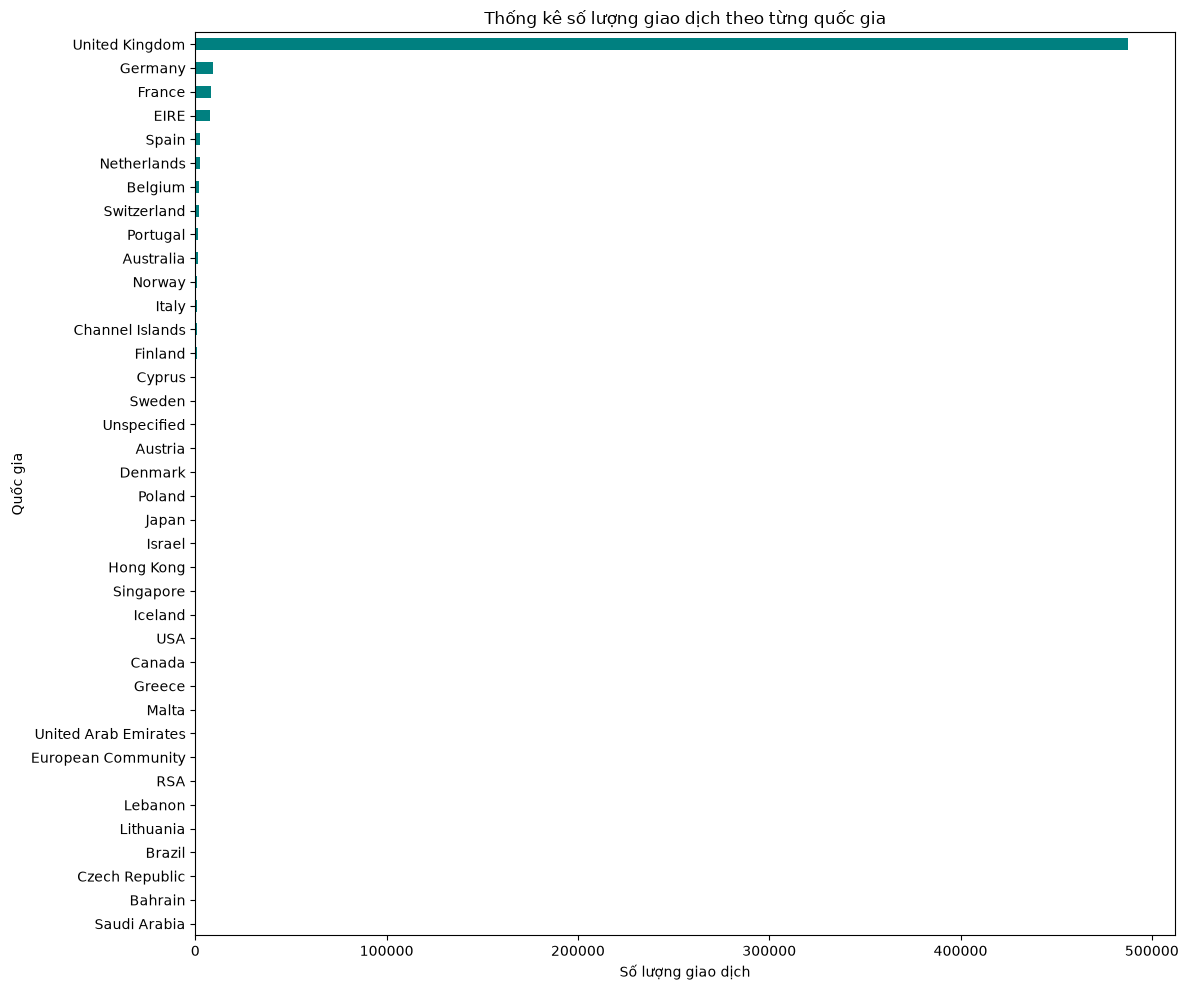

In [3]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 3: Thống kê số lượng dòng dữ liệu theo từng quốc gia
import pandas as pd
import matplotlib.pyplot as plt

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/Online Retail.xlsx")
df['Description'] = df['Description'].astype(str).str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.contains('C')]

plt.figure(figsize=(12, 10))
df['Country'].value_counts().plot(kind='barh', color='teal')
plt.title('Thống kê số lượng giao dịch theo từng quốc gia')
plt.xlabel('Số lượng giao dịch')
plt.ylabel('Quốc gia')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(r"figures/p2_b2_t37_c3_country.png", dpi=150)
plt.show()

print("Nhận xét: Nước Anh (United Kingdom) chiếm đại đa số các giao dịch của cửa hàng trực tuyến, vượt trội hoàn toàn so với các quốc gia khác.")


### Câu 4

In [4]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 4: Lọc dữ liệu UK và chuyển sang dạng ma trận One-hot encoding
import pandas as pd
import numpy as np

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/Online Retail.xlsx")
df['Description'] = df['Description'].astype(str).str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.contains('C')]

basket = (df[df['Country'] == "United Kingdom"]
          .groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

# Biến đổi vector hóa thành One-hot encoding (0 hoặc 1)
basket_sets = (basket >= 1).astype(int)

# Xóa cột POSTAGE nếu có
if 'POSTAGE' in basket_sets.columns:
    basket_sets = basket_sets.drop(columns=['POSTAGE'])

print(f"Kích thước ma trận giao dịch UK: {basket_sets.shape}")
print("10 cột sản phẩm đầu tiên của 5 hóa đơn:")
print(basket_sets.iloc[:5, :10])


Ngô Minh Khôi - 6451071037
Kích thước ma trận giao dịch UK: (18668, 4175)
10 cột sản phẩm đầu tiên của 5 hóa đơn:
Description  *Boombox Ipod Classic  ...  12 PENCIL SMALL TUBE WOODLAND
InvoiceNo                           ...                               
536365                           0  ...                              0
536366                           0  ...                              0
536367                           0  ...                              0
536368                           0  ...                              0
536369                           0  ...                              0

[5 rows x 10 columns]


### Câu 5

In [5]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 5: Tìm tập phổ biến bằng Apriori (min_sup=3%) và tạo luật kết hợp (min_conf=50%)
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/Online Retail.xlsx")
df['Description'] = df['Description'].astype(str).str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.contains('C')]

basket = (df[df['Country'] == "United Kingdom"]
          .groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket_sets = (basket >= 1).astype(int)
if 'POSTAGE' in basket_sets.columns:
    basket_sets = basket_sets.drop(columns=['POSTAGE'])

frequent_itemsets = apriori(basket_sets.astype(bool), min_support=0.03, use_colnames=True)
print(f"Tổng số tập phổ biến tìm được (min_sup=3%): {len(frequent_itemsets)}")
print("--- 10 tập phổ biến đầu tiên ---")
print(frequent_itemsets.head(10))

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)
rules["antecedents_str"] = rules["antecedents"].apply(lambda x: ', '.join(list(x)))
rules["consequents_str"] = rules["consequents"].apply(lambda x: ', '.join(list(x)))

print(f"\nTổng số luật kết hợp tìm được (min_conf=50%): {len(rules)}")
print("--- Danh sách các luật kết hợp (Antecedent => Consequent) ---")
for idx, r in rules.iterrows():
    print(f"{r['antecedents_str']} => {r['consequents_str']} [Support: {r['support']:.4f}, Confidence: {r['confidence']:.4f}, Lift: {r['lift']:.4f}]")


Ngô Minh Khôi - 6451071037
Tổng số tập phổ biến tìm được (min_sup=3%): 131
--- 10 tập phổ biến đầu tiên ---
    support                                      itemsets
0  0.045800           frozenset({6 RIBBONS RUSTIC CHARM})
1  0.031123  frozenset({60 CAKE CASES VINTAGE CHRISTMAS})
2  0.040336      frozenset({60 TEATIME FAIRY CAKE CASES})
3  0.046925       frozenset({ALARM CLOCK BAKELIKE GREEN})
4  0.035140        frozenset({ALARM CLOCK BAKELIKE PINK})
5  0.049818         frozenset({ALARM CLOCK BAKELIKE RED})
6  0.036212     frozenset({ANTIQUE SILVER T-LIGHT GLASS})
7  0.073441    frozenset({ASSORTED COLOUR BIRD ORNAMENT})
8  0.042265     frozenset({BAKING SET 9 PIECE RETROSPOT})
9  0.035087              frozenset({BATHROOM METAL SIGN})

Tổng số luật kết hợp tìm được (min_conf=50%): 10
--- Danh sách các luật kết hợp (Antecedent => Consequent) ---
ALARM CLOCK BAKELIKE RED => ALARM CLOCK BAKELIKE GREEN [Support: 0.0302, Confidence: 0.6054, Lift: 12.9009]
ALARM CLOCK BAKELIKE GREEN => ALAR

### Câu 6

Ngô Minh Khôi - 6451071037
--- SO SÁNH HIỆU NĂNG GIỮA APRIORI VÀ FP-GROWTH (min_sup = 3%) ---
1. Số tập phổ biến tìm được: Apriori = 131, FP-Growth = 131
2. Thời gian thực thi: Apriori = 3.2485s, FP-Growth = 4.9367s
Nhận xét: Cả hai thuật toán đều cho ra kết quả tập phổ biến chính xác như nhau, tuy nhiên FP-Growth tiết kiệm thời gian hơn do cấu trúc cây FP nén không phải sinh tập ứng viên.


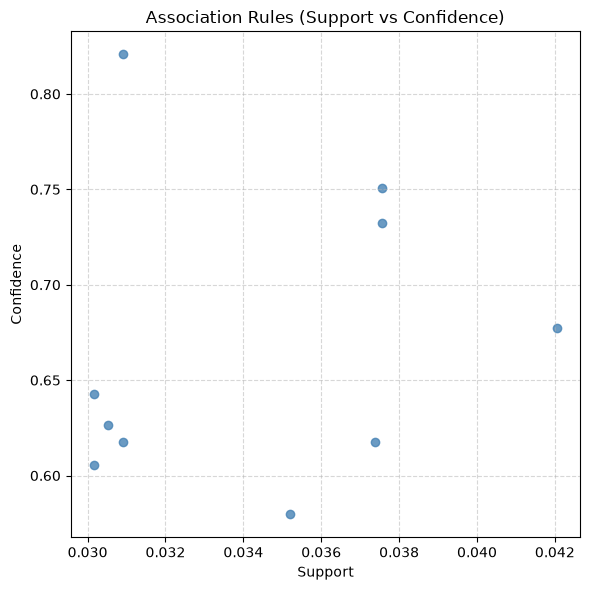

In [6]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 6: Biểu đồ scatter plot luật kết hợp & so sánh với FP-Growth
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/Online Retail.xlsx")
df['Description'] = df['Description'].astype(str).str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.contains('C')]

basket = (df[df['Country'] == "United Kingdom"]
          .groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket_sets = (basket >= 1).astype(int)
if 'POSTAGE' in basket_sets.columns:
    basket_sets = basket_sets.drop(columns=['POSTAGE'])

t0 = time.time()
frequent_itemsets_ap = apriori(basket_sets.astype(bool), min_support=0.03, use_colnames=True)
t_ap = time.time() - t0

t0 = time.time()
frequent_itemsets_fp = fpgrowth(basket_sets.astype(bool), min_support=0.03, use_colnames=True)
t_fp = time.time() - t0

rules = association_rules(frequent_itemsets_ap, metric="confidence", min_threshold=0.5)

plt.figure(figsize=(6, 6))
plt.title('Association Rules (Support vs Confidence)')
plt.xlabel('Support')
plt.ylabel('Confidence')
sns.regplot(x=rules['support'].values, y=rules['confidence'].values, fit_reg=False, color='steelblue')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(r"figures/p2_b2_t37_c6_rules.png", dpi=150)
plt.show()

print(f"--- SO SÁNH HIỆU NĂNG GIỮA APRIORI VÀ FP-GROWTH (min_sup = 3%) ---")
print(f"1. Số tập phổ biến tìm được: Apriori = {len(frequent_itemsets_ap)}, FP-Growth = {len(frequent_itemsets_fp)}")
print(f"2. Thời gian thực thi: Apriori = {t_ap:.4f}s, FP-Growth = {t_fp:.4f}s")
print(f"Nhận xét: Cả hai thuật toán đều cho ra kết quả tập phổ biến chính xác như nhau, tuy nhiên FP-Growth tiết kiệm thời gian hơn do cấu trúc cây FP nén không phải sinh tập ứng viên.")
